# 02 · Análisis exploratorio del consumo eléctrico de Brasil
Enfoque adaptado del [notebook de Katherine Varela](https://github.com/katherinevarela775/C1DS-Price_Analysis/blob/main/notebooks/energy_analysis.ipynb):
inspección, distribuciones, segmentación temporal, tendencia, geografía, consumo y consumidores.
Para cumplir el enunciado usamos [Brazil's energy consumption, lucasdasilvadantas](https://www.kaggle.com/datasets/lucasdasilvadantas/brazils-energy-consumption),
publicado a partir de datos de **EPE**. Es un Excel de registros mensuales por UF y segmento.
Su período y dimensiones se calculan abajo; no trasladamos cifras de la otra versión del repo.

Preguntas: ¿cómo se distribuyen consumo y consumidores? ¿Qué diferencias hay por mercado y sector?
¿Cómo varía el consumo mensual? ¿Qué estados concentran el consumo registrado?
Esta fuente contiene consumo y unidades consumidoras, no precio ni horarios baratos.
Orden obligatorio: exploración → limpieza → análisis simple → análisis complejo.

## Cómo ejecutar este notebook
Entregable autocontenido: solo necesitás este `.ipynb`, un kernel Python con pip y conexión a internet.
Reiniciá el kernel y ejecutá todas las celdas de arriba abajo.
La primera celda instala librerías faltantes; la siguiente descarga el ZIP público de Kaggle
y lee el archivo en memoria. No necesita `data/`, `scripts/`, `docs/`, `memory/` ni `outputs/`.
Los resultados y gráficos quedan dentro del notebook, sin crear CSV ni carpetas de salida.

Verificado con Python 3.11, Pandas 2.2.3, NumPy 2.1.3, Matplotlib 3.9.4 y Seaborn 0.13.2.
Para Brasil también se utiliza python-calamine 0.3.1 para leer el Excel.
En Kaggle, habilitá internet para ejecutar y vinculá el dataset correspondiente al publicar.
Una revisión del dataset puede cambiar los resultados; se imprime el hash del archivo descargado.

In [1]:
# Instala en este kernel solo las librerías que falten.
import importlib.util
import subprocess
import sys

paquetes = {'pandas': 'pandas==2.2.3', 'numpy': 'numpy==2.1.3', 'matplotlib': 'matplotlib==3.9.4', 'seaborn': 'seaborn==0.13.2', 'python_calamine': 'python-calamine==0.3.1'}
faltantes = [paquete for modulo, paquete in paquetes.items()
             if importlib.util.find_spec(modulo) is None]
if faltantes:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltantes])
print("Librerías disponibles para ejecutar el notebook.")

Librerías disponibles para ejecutar el notebook.


In [2]:
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.max_columns", 12)
SEMILLA = 42

# Descarga el dataset público de Kaggle en cada ejecución.
URL = "https://www.kaggle.com/api/v1/datasets/download/lucasdasilvadantas/brazils-energy-consumption"
with urlopen(URL, timeout=90) as respuesta:
    comprimido = respuesta.read()
with ZipFile(BytesIO(comprimido)) as zip_datos:
    contenido = zip_datos.read("Dados brutos.xlsx")
raw = pd.read_excel(BytesIO(contenido), engine="calamine")
print("Dataset:", "lucasdasilvadantas/brazils-energy-consumption")
print("Archivo:", "Dados brutos.xlsx", "| Filas y columnas:", raw.shape)
print("SHA-256:", hashlib.sha256(contenido).hexdigest())

def mostrar():
    plt.tight_layout()
    plt.show()
    plt.close("all")

Dataset: lucasdasilvadantas/brazils-energy-consumption
Archivo: Dados brutos.xlsx | Filas y columnas: (285499, 14)
SHA-256: d0292b0e37bbbd8eb332bc951312851e97cb5e36f10f9f1aef49b4d60e29662d


## 1. Exploración de las características
| Columna | Significado |
|---|---|
| Data | Mes de referencia, entero AAAAMMDD |
| UF / Sistema | Estado brasileño / sistema eléctrico |
| TipoConsumidor | Cativo (regulado) / Livre (libre) |
| Setor Econômico - N1/N2/N3 | Clasificación jerárquica del sector |
| Tipo Tensão - N1/N2/N3 | Clasificación de tensión |
| Faixa de Consumo N1/N2 | Franja de consumo; sus etiquetas en kWh no cambian la unidad de Consumo |
| Consumo | Energía registrada en MWh |
| Consumidores | Cantidad de unidades consumidoras de ese segmento, no población |

Una fila es **un mes de un segmento**, no una factura ni un consumidor individual.
Varios segmentos comparten fecha; por eso las fechas repetidas son válidas.
Fuente institucional: [EPE](https://www.epe.gov.br/pt/publicacoes-dados-abertos/dados-abertos/dados-do-consumo-mensal-de-energia-eletrica).

In [3]:
display(raw.head())
raw.info()
display(raw[["Consumo", "Consumidores"]].describe().round(2))
display(pd.DataFrame({"nulos": raw.isna().sum(), "porcentaje": raw.isna().mean() * 100}).round(2))
print("Filas idénticas:", raw.duplicated().sum())
for columna in ["TipoConsumidor", "Sistema", "UF", "Setor Econômico - N1"]:
    display(raw[columna].value_counts().to_frame("registros"))

,Data,TipoConsumidor,Sistema,UF,Setor Econômico - N1,Setor Econômico - N2,...,Tipo Tensão - N2,Tipo Tensão - N3,Faixa de Consumo N1,Faixa de Consumo N2,Consumidores,Consumo
0,20140101,Cativo,Sudeste / Centro-Oeste,RO,Residencial,Convencional (Excepto Baixa Renda),...,TOTAL,TOTAL,Alta Tensão,Alta Tensão,1.0,8.0
1,20140201,Cativo,Sudeste / Centro-Oeste,RO,Residencial,Convencional (Excepto Baixa Renda),...,TOTAL,TOTAL,Alta Tensão,Alta Tensão,1.0,8.0
2,20140301,Cativo,Sudeste / Centro-Oeste,RO,Residencial,Convencional (Excepto Baixa Renda),...,TOTAL,TOTAL,Alta Tensão,Alta Tensão,1.0,9.0
3,20140401,Cativo,Sudeste / Centro-Oeste,RO,Residencial,Convencional (Excepto Baixa Renda),...,TOTAL,TOTAL,Alta Tensão,Alta Tensão,1.0,10.0
4,20140501,Cativo,Sudeste / Centro-Oeste,RO,Residencial,Convencional (Excepto Baixa Renda),...,TOTAL,TOTAL,Alta Tensão,Alta Tensão,1.0,9.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 285499 entries, 0 to 285498
Data columns (total 14 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Data                  285499 non-null  int64  
 1   TipoConsumidor        285499 non-null  object 
 2   Sistema               285499 non-null  object 
 3   UF                    285499 non-null  object 
 4   Setor Econômico - N1  285499 non-null  object 
 5   Setor Econômico - N2  285499 non-null  object 
 6   Setor Econômico - N3  285499 non-null  object 
 7   Tipo Tensão - N1      285499 non-null  object 
 8   Tipo Tensão - N2      285499 non-null  object 
 9   Tipo Tensão - N3      285499 non-null  object 
 10  Faixa de Consumo N1   285499 non-null  object 
 11  Faixa de Consumo N2   285499 non-null  object 
 12  Consumidores          281511 non-null  float64
 13  Consumo               275799 non-null  float64
dtypes: float64(2), int64(1), object(11)
memory usage: 30

,Consumo,Consumidores
count,275799.00,281511.00
mean,17584.21,35721.26
std,75101.92,207818.06
min,-209308.00,-51088.00
25%,109.00,9.00
50%,1470.00,132.00
75%,9614.00,3222.00
max,1850736.20,6652168.00


,nulos,porcentaje
Data,0,0.0
TipoConsumidor,0,0.0
Sistema,0,0.0
UF,0,0.0
Setor Econômico - N1,0,0.0
Setor Econômico - N2,0,0.0
Setor Econômico - N3,0,0.0
Tipo Tensão - N1,0,0.0
Tipo Tensão - N2,0,0.0
Tipo Tensão - N3,0,0.0


Filas idénticas: 0


,registros
TipoConsumidor,
Cativo,251992
Livre,33507


,registros
Sistema,
Sudeste / Centro-Oeste,100666
Nordeste,78020
Sul,37762
Sistemas Isolados,34639
Norte Interligado,34412


,registros
UF,
PA,17638
PR,14736
PE,14729
RJ,14427
SP,14151
BA,13607
RS,13268
MG,12995
MT,12576


,registros
Setor Econômico - N1,
Residencial,80514
Comercial,70184
Rural,46272
Poder Público,30078
Industrial,26423
Serviço Público,17371
Consumo Próprio,9327
Iluminação Pública,5330


## 2. Limpieza y preprocesamiento
Conservamos `raw`. Renombramos el sector principal a `Classe`, como en la referencia.
Convertimos Data con formato explícito y ordenamos. Todas las dimensiones junto con la fecha
forman la clave de un segmento; si esa clave se repite, se debe investigar, no promediar en silencio.

Conservamos nulos y valores no positivos en `base`. Para relaciones consumo/consumidores usamos `df`
con ambas mediciones presentes. Para sumas mensuales usamos todo Consumo disponible en `base`,
aunque falte Consumidores, y mostramos cobertura. Un total observado con faltantes puede subestimar
el total verdadero; no rellenamos automáticamente con cero ni mediana.

In [4]:
base = raw.copy().rename(columns={"Setor Econômico - N1": "Classe"})
dimensiones = [c for c in base.columns if c not in ["Data", "Consumo", "Consumidores"]]
for columna in dimensiones:
    base[columna] = base[columna].astype("string").str.strip()
base["Data"] = pd.to_datetime(base["Data"].astype(str), format="%Y%m%d", errors="raise")
assert base["Data"].dt.day.eq(1).all(), "Revisar frecuencia mensual"
assert not base.duplicated(["Data"] + dimensiones).any(), "Clave de segmento repetida"
base = base.sort_values("Data").set_index("Data")
df = base.dropna(subset=["Consumo", "Consumidores"]).copy()
auditoria = pd.Series({
    "filas_originales": len(base), "filas_con_ambas_mediciones": len(df),
    "sin_alguna_medicion": len(base) - len(df),
    "consumo_negativo": int(base["Consumo"].lt(0).sum()),
    "consumo_cero": int(base["Consumo"].eq(0).sum()),
    "consumidores_no_positivos": int(base["Consumidores"].le(0).sum()),
    "meses": base.index.to_period("M").nunique(),
})
display(auditoria.to_frame("resultado"))
print("Período:", base.index.min().date(), "→", base.index.max().date())
display(base.loc[base["Consumo"] < 0, ["UF", "TipoConsumidor", "Consumo"]].head())

,resultado
filas_originales,285499
filas_con_ambas_mediciones,271811
sin_alguna_medicion,13688
consumo_negativo,635
consumo_cero,0
consumidores_no_positivos,59
meses,120


Período: 2014-01-01 → 2023-12-01


,UF,TipoConsumidor,Consumo
Data,,,
2014-01-01,RO,Cativo,-2.0
2014-01-01,RO,Cativo,-99.0
2014-01-01,ES,Cativo,-2068.0
2014-01-01,RO,Cativo,-40.0
2014-01-01,PA,Cativo,-881.0


### Números negativos, ceros y la etiqueta TOTAL
Un logaritmo solo admite valores positivos. Creamos subconjuntos positivos para esas visualizaciones,
pero no borramos los valores no positivos de los totales. La fuente no prueba que cada negativo
sea inyección a la red; no atribuimos esa causa. Incluso hay negativos en registros Cativo.

`TOTAL` en un nivel inferior puede significar que no existe desglose. Verificamos en este archivo
que, para el mismo grupo padre, no coexistan ese subtotal y sus detalles en los niveles de sector/tensión.
La verificación evita sumar dos veces el mismo agregado en las dimensiones presentes.

In [5]:
padres = ["UF", "Sistema", "TipoConsumidor", "Classe"]
tension = ["Tipo Tensão - N1", "Tipo Tensão - N2", "Tipo Tensão - N3"]
franjas = ["Faixa de Consumo N1", "Faixa de Consumo N2"]
chequeos = [
    ("Setor Econômico - N2", padres + tension + franjas),
    ("Setor Econômico - N3", padres + ["Setor Econômico - N2"] + tension + franjas),
    ("Tipo Tensão - N2", padres + ["Setor Econômico - N2", "Setor Econômico - N3", "Tipo Tensão - N1"] + franjas),
    ("Tipo Tensão - N3", padres + ["Setor Econômico - N2", "Setor Econômico - N3", "Tipo Tensão - N1", "Tipo Tensão - N2"] + franjas),
]
revision = {}
for nivel, grupo in chequeos:
    grupos = base.reset_index().groupby(["Data"] + grupo)[nivel]
    conflicto = grupos.agg(lambda s: "TOTAL" in set(s) and len(set(s)) > 1)
    revision[nivel] = int(conflicto.sum())
display(pd.Series(revision).to_frame("grupos con TOTAL y detalle"))
assert not any(revision.values()), "Revisar jerarquía antes de sumar"
positivos = df.loc[df["Consumo"].gt(0) & df["Consumidores"].gt(0)].copy()
print("Registros completos y positivos para escala log:", len(positivos))

,grupos con TOTAL y detalle
Setor Econômico - N2,0
Setor Econômico - N3,0
Tipo Tensão - N2,0
Tipo Tensão - N3,0


Registros completos y positivos para escala log: 271211


## 3. Análisis simple
### 3.1 Distribuciones individuales
Como en el repo de referencia, mostramos histograma y boxplot de consumo y consumidores.
La escala logarítmica permite ver valores de tamaños muy distintos. Media y mediana se calculan
sobre el subconjunto positivo de cada variable; su denominador se muestra en la tabla.

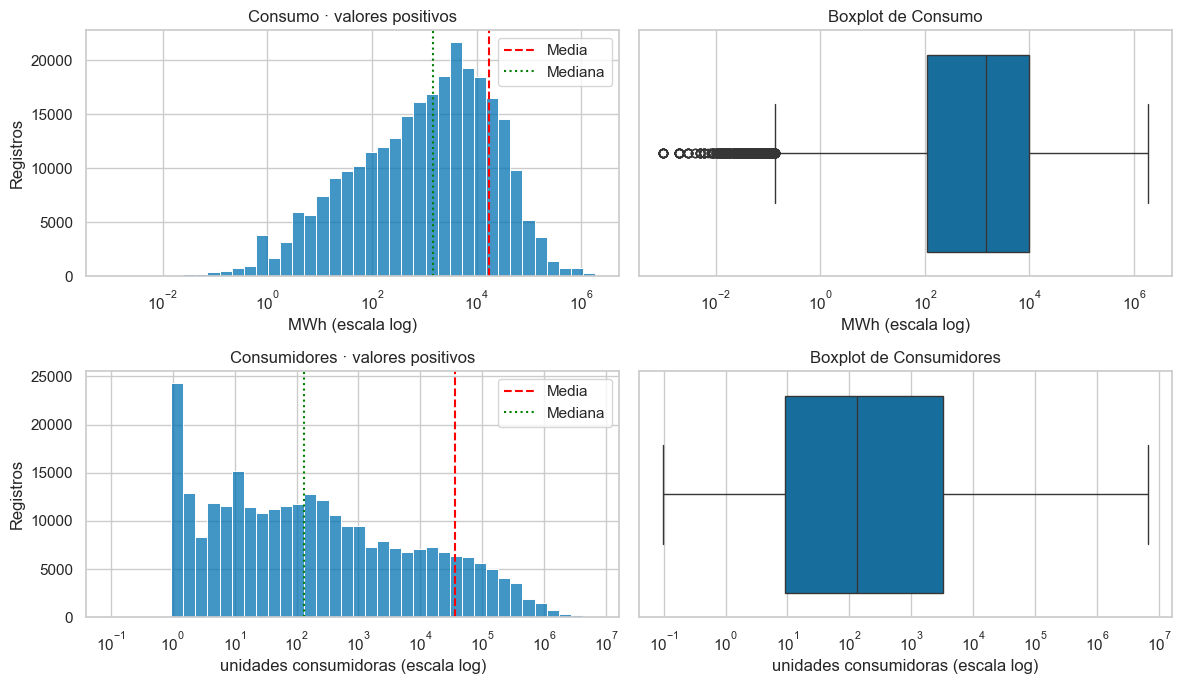

,n,media,mediana
Consumo,275164.0,17630.61,1484.0
Consumidores,281452.0,35728.99,132.0


In [6]:
fig, ejes = plt.subplots(2, 2, figsize=(12, 7))
resumen_distribuciones = {}
for fila, columna, unidad in [(0, "Consumo", "MWh"), (1, "Consumidores", "unidades consumidoras")]:
    valores = base.loc[base[columna] > 0, columna]
    resumen_distribuciones[columna] = {"n": len(valores), "media": valores.mean(), "mediana": valores.median()}
    sns.histplot(x=valores, bins=40, log_scale=True, ax=ejes[fila, 0])
    ejes[fila, 0].axvline(valores.mean(), color="red", ls="--", label="Media")
    ejes[fila, 0].axvline(valores.median(), color="green", ls=":", label="Mediana")
    ejes[fila, 0].set(title=columna + " · valores positivos", xlabel=unidad + " (escala log)", ylabel="Registros")
    ejes[fila, 0].legend()
    sns.boxplot(x=valores, log_scale=True, ax=ejes[fila, 1])
    ejes[fila, 1].set(title="Boxplot de " + columna, xlabel=unidad + " (escala log)")
mostrar()
display(pd.DataFrame(resumen_distribuciones).T.round(2))

### 3.2 Distribuciones segmentadas y filtros
Comparamos Cativo/Livre y sectores usando registros positivos para la escala log.
El filtro sectorial Residencial/Industrial responde una comparación concreta.
La mediana por registro no es consumo medio por cliente: las filas son segmentos de tamaños diferentes.

,count,mean,median
TipoConsumidor,,,
Cativo,244001,13274.14,1112.32
Livre,31798,50657.41,5794.63


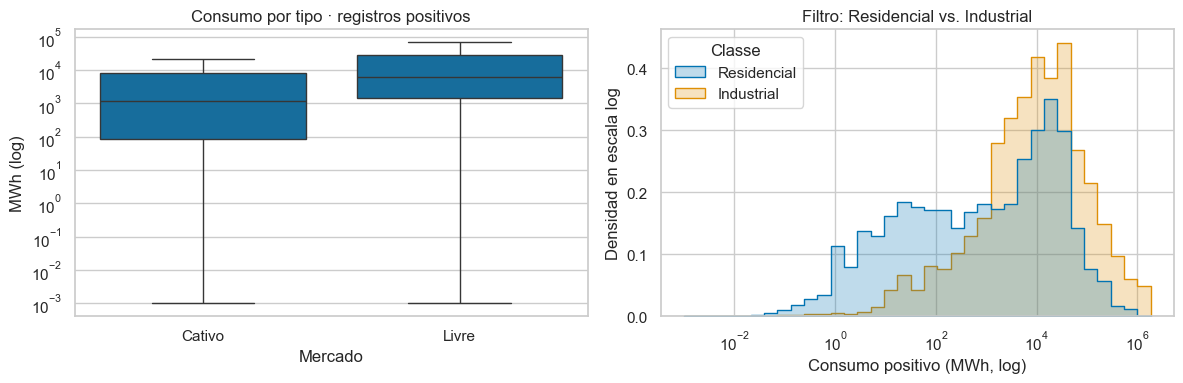

In [7]:
por_tipo = base.groupby("TipoConsumidor")["Consumo"].agg(["count", "mean", "median"])
display(por_tipo.round(2))
sectores = positivos.loc[positivos["Classe"].isin(["Residencial", "Industrial"])]
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=positivos, x="TipoConsumidor", y="Consumo", showfliers=False, ax=ejes[0])
ejes[0].set_yscale("log")
ejes[0].set(title="Consumo por tipo · registros positivos", xlabel="Mercado", ylabel="MWh (log)")
sns.histplot(data=sectores, x="Consumo", hue="Classe", bins=35, log_scale=True,
             stat="density", common_norm=False, element="step", ax=ejes[1])
ejes[1].set(title="Filtro: Residencial vs. Industrial", xlabel="Consumo positivo (MWh, log)", ylabel="Densidad en escala log")
mostrar()

### 3.3 Segmentación temporal por mes y año
Un boxplot por mes compara las distribuciones de registros positivos, no los totales nacionales.
Para resumir los años mostramos media, mediana y banda P25–P75 entre registros.
Esa banda es dispersión del dataset; no es un intervalo de confianza.

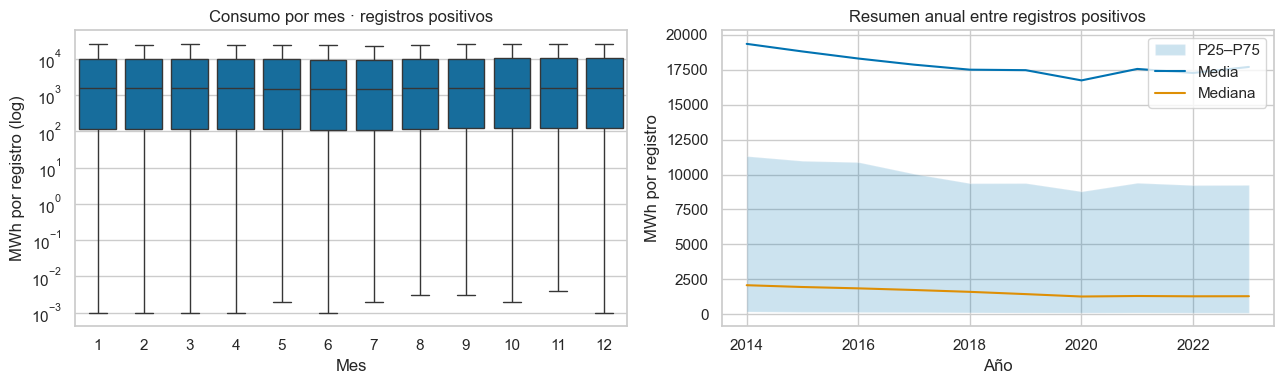

,count,mean,50%,25%,75%
anio,,,,,
2014,24319.0,19364.73,2067.00,180.00,11324.50
2015,24676.0,18819.19,1938.50,149.00,10986.00
2016,25138.0,18313.37,1842.00,142.00,10892.00
2017,25942.0,17873.63,1724.50,133.00,10057.25
2018,27127.0,17514.64,1591.42,116.09,9381.22
2019,27588.0,17479.20,1429.00,107.20,9387.94
2020,28415.0,16746.31,1257.18,96.94,8795.59
2021,28563.0,17567.57,1294.41,105.84,9408.61
2022,29430.0,17279.66,1271.94,96.00,9245.47


In [8]:
positivos["mes"] = positivos.index.month
positivos["anio"] = positivos.index.year
anual_registros = positivos.groupby("anio")["Consumo"].describe()
fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=positivos, x="mes", y="Consumo", showfliers=False, ax=ejes[0])
ejes[0].set_yscale("log")
ejes[0].set(title="Consumo por mes · registros positivos", xlabel="Mes", ylabel="MWh por registro (log)")
ejes[1].fill_between(anual_registros.index, anual_registros["25%"], anual_registros["75%"], alpha=0.2, label="P25–P75")
ejes[1].plot(anual_registros.index, anual_registros["mean"], label="Media")
ejes[1].plot(anual_registros.index, anual_registros["50%"], label="Mediana")
ejes[1].set(title="Resumen anual entre registros positivos", xlabel="Año", ylabel="MWh por registro")
ejes[1].legend()
mostrar()
display(anual_registros[["count", "mean", "50%", "25%", "75%"]].round(2))

### 3.4 Correlación y recta descriptiva
Pearson sobre registros completos mide asociación lineal, no causalidad.
La recta ajustada es una visualización descriptiva, no un modelo validado para predecir.
Usamos todos los registros completos para correlación y hasta 1.000 para la dispersión/recta.
No afirmamos que cantidad de consumidores sea el principal motor del consumo a partir de esto.

,Consumidores,Consumo
Consumidores,1.000,0.396
Consumo,0.396,1.000


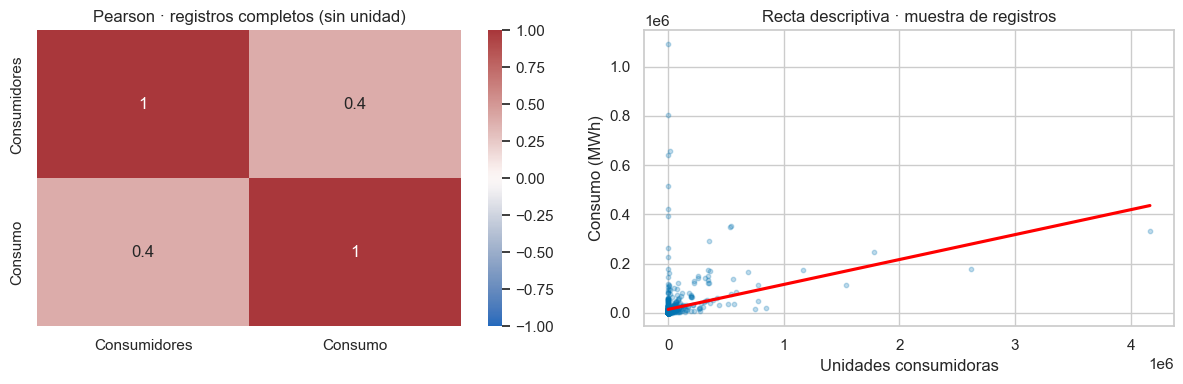

In [9]:
correlacion = df[["Consumidores", "Consumo"]].corr()
display(correlacion.round(3))
muestra_completa = df.sample(n=min(1000, len(df)), random_state=SEMILLA)
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(correlacion, annot=True, vmin=-1, vmax=1, center=0, cmap="vlag", ax=ejes[0])
ejes[0].set_title("Pearson · registros completos (sin unidad)")
sns.regplot(data=muestra_completa, x="Consumidores", y="Consumo", ci=None,
            scatter_kws={"s": 10, "alpha": 0.25}, line_kws={"color": "red"}, ax=ejes[1])
ejes[1].set(title="Recta descriptiva · muestra de registros", xlabel="Unidades consumidoras", ylabel="Consumo (MWh)")
mostrar()

### 3.5 Pairplot
Para mejorar legibilidad transformamos dos variables positivas a log10.
Un valor 3 en el eje log10 representa 1.000 en la unidad original.
No sustituimos con logaritmos las variables de la correlación anterior.
La muestra fija es solo para visualización; se etiqueta por tipo de consumidor.

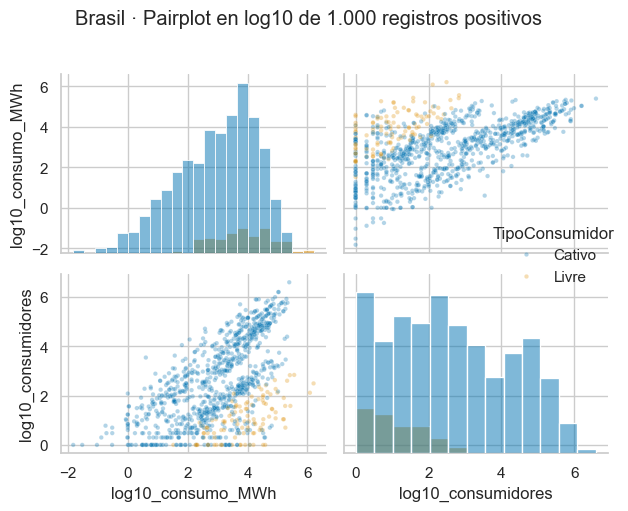

In [10]:
muestra = positivos.sample(n=min(1000, len(positivos)), random_state=SEMILLA).copy()
muestra["log10_consumo_MWh"] = np.log10(muestra["Consumo"])
muestra["log10_consumidores"] = np.log10(muestra["Consumidores"])
g = sns.pairplot(muestra, vars=["log10_consumo_MWh", "log10_consumidores"],
                 hue="TipoConsumidor", diag_kind="hist", plot_kws={"alpha": 0.3, "s": 10})
g.fig.suptitle("Brasil · Pairplot en log10 de 1.000 registros positivos", y=1.02)
mostrar()

## 4. Análisis complejo
### 4.1 Serie mensual y media móvil de 12 meses
Sumamos MWh de segmentos distintos del mismo mes. Energía se suma; una media entre segmentos
respondería otra pregunta. `sum(min_count=1)` evita convertir un mes sin datos en cero.
La cobertura mide registros con dato sobre filas declaradas del mes, no segmentos que nunca aparecieron.
La media móvil es retrospectiva y usa 12 meses completos, sin ventana centrada ni datos futuros.

,Consumo,Consumidores,registros,consumo_presente,cobertura_pct,media_movil_12
Data,,,,,,
2014-01-01,40279759.00,75036817.0,2134,2053,96.20,NaN
2014-02-01,41653487.00,75282897.0,2136,2047,95.83,NaN
2014-03-01,40315392.00,75468866.0,2135,2053,96.16,NaN
2014-04-01,39550251.00,75650388.0,2136,2053,96.11,NaN
2014-05-01,39100499.00,75858810.0,2141,2049,95.70,NaN
2014-06-01,37726472.88,76014514.0,2136,2048,95.88,NaN
2014-07-01,37866809.00,76213682.0,2143,2052,95.75,NaN
2014-08-01,38550694.00,76321200.0,2143,2055,95.89,NaN
2014-09-01,38894976.00,76622551.0,2142,2060,96.17,NaN


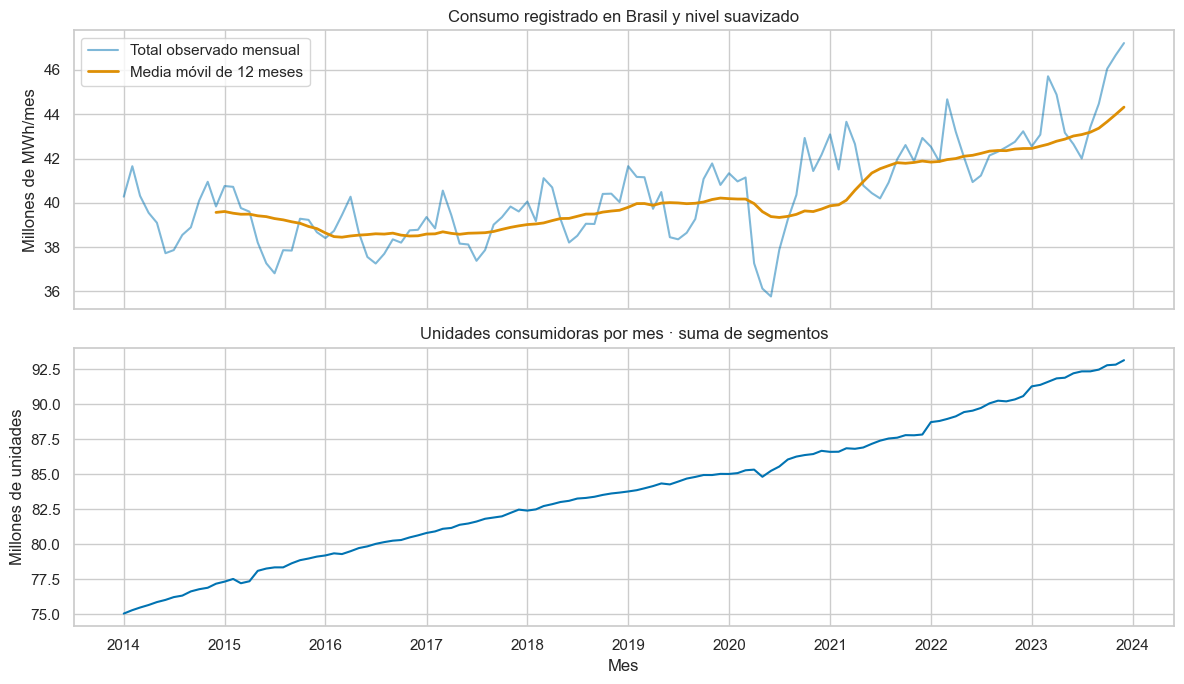

In [11]:
mensual = base[["Consumo", "Consumidores"]].resample("MS").sum(min_count=1)
mensual["registros"] = base["Consumo"].resample("MS").size()
mensual["consumo_presente"] = base["Consumo"].resample("MS").count()
mensual["cobertura_pct"] = mensual["consumo_presente"] / mensual["registros"] * 100
mensual["media_movil_12"] = mensual["Consumo"].rolling(12, min_periods=12).mean()
display(mensual.head(12).round(2))
fig, ejes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ejes[0].plot(mensual.index, mensual["Consumo"] / 1e6, alpha=0.5, label="Total observado mensual")
ejes[0].plot(mensual.index, mensual["media_movil_12"] / 1e6, lw=2, label="Media móvil de 12 meses")
ejes[0].set(title="Consumo registrado en Brasil y nivel suavizado", ylabel="Millones de MWh/mes")
ejes[0].legend()
ejes[1].plot(mensual.index, mensual["Consumidores"] / 1e6)
ejes[1].set(title="Unidades consumidoras por mes · suma de segmentos", xlabel="Mes", ylabel="Millones de unidades")
mostrar()

### 4.2 Patrón por mes: comparar años, no copiar una estación esperada
El heatmap año/mes permite comprobar si los meses altos se repiten.
Los totales mensuales también cambian por crecimiento y composición, por lo que un pico
promedio no demuestra que el clima lo cause. No asumimos el patrón diciembre–marzo de otra versión.

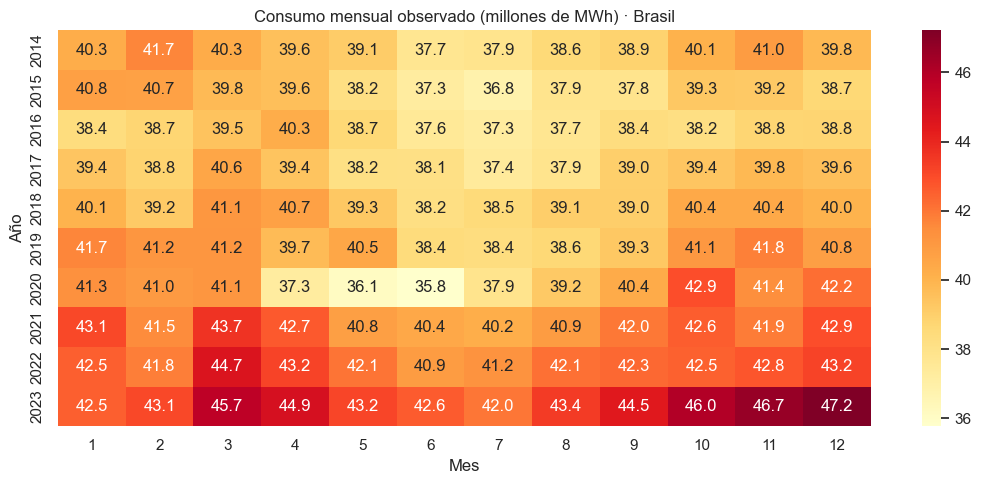

,count,mean,median
mes,,,
1,10,41002934.25,41047963.35
2,10,40770341.73,41069474.03
3,10,41754615.38,41128887.87
4,10,40731606.33,40003793.59
5,10,39600276.80,39184174.25
6,10,38713210.16,38164189.41
7,10,38750893.24,38113573.79
8,10,39541121.29,38852413.00
9,10,40153275.14,39157979.89


In [12]:
calendario = mensual.copy()
calendario["anio"] = calendario.index.year
calendario["mes"] = calendario.index.month
matriz = calendario.pivot(index="anio", columns="mes", values="Consumo")
plt.figure(figsize=(11, 5))
sns.heatmap(matriz / 1e6, annot=True, fmt=".1f", cmap="YlOrRd")
plt.title("Consumo mensual observado (millones de MWh) · Brasil")
plt.xlabel("Mes")
plt.ylabel("Año")
mostrar()
patron_mes = calendario.groupby("mes")["Consumo"].agg(["count", "mean", "median"])
display(patron_mes.round(2))

### 4.3 Estados y sectores
Ahora usamos UF, disponible en el dataset del enunciado. Sumamos energía de todo el período
observado y mostramos sus cinco estados principales. El número de filas no indica consumo.
Para consumidores mostramos un mes concreto: sumarlos entre años no cuenta personas únicas.

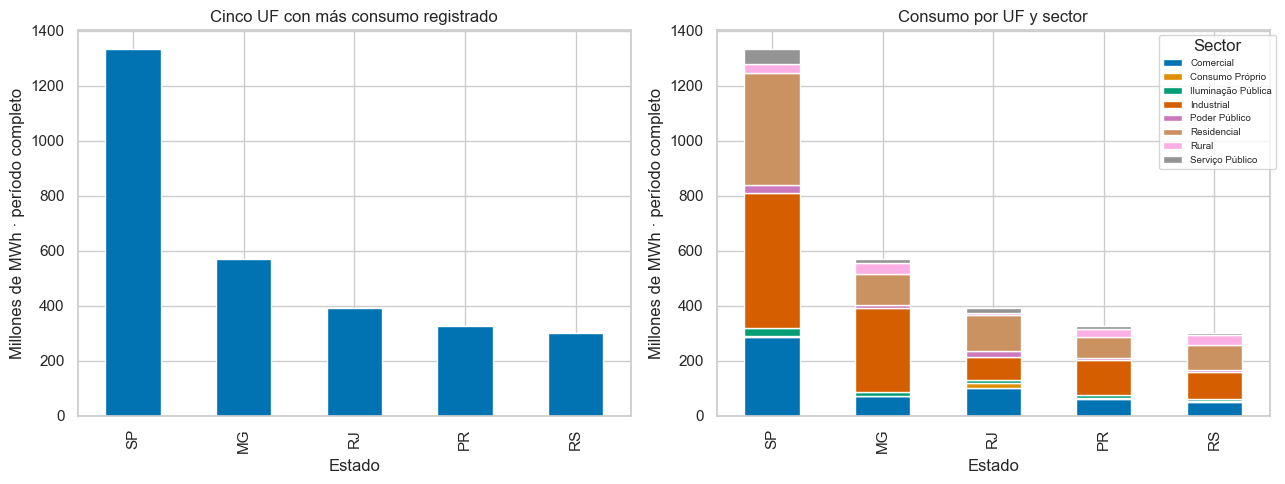

,MWh observados
UF,
SP,1.335301e+09
MG,5.702171e+08
RJ,3.912556e+08
PR,3.248535e+08
RS,3.022107e+08


,unidades en último mes
UF,
SP,21137187.0
MG,9905239.0
RJ,7847249.0
BA,6647088.0
PR,5259832.0


In [13]:
por_uf = base.groupby("UF")["Consumo"].sum(min_count=1).sort_values(ascending=False)
top_uf = por_uf.head(5)
por_sector = base.pivot_table(index="UF", columns="Classe", values="Consumo", aggfunc="sum")
fig, ejes = plt.subplots(1, 2, figsize=(13, 5))
(top_uf / 1e6).plot.bar(ax=ejes[0])
ejes[0].set(title="Cinco UF con más consumo registrado", xlabel="Estado", ylabel="Millones de MWh · período completo")
(por_sector.loc[top_uf.index] / 1e6).plot.bar(stacked=True, ax=ejes[1])
ejes[1].set(title="Consumo por UF y sector", xlabel="Estado", ylabel="Millones de MWh · período completo")
ejes[1].legend(title="Sector", bbox_to_anchor=(1.02, 1), fontsize=7)
mostrar()
display(top_uf.to_frame("MWh observados"))
ultimo_mes = mensual.index.max()
display(base.loc[base.index == ultimo_mes].groupby("UF")["Consumidores"].sum(min_count=1).nlargest(5).to_frame("unidades en último mes"))

### 4.4 Cativo vs. Livre: total e intensidad entre grupos comparables
Agrupamos por mes y tipo, sumando consumo/consumidores de registros donde ambas mediciones existen.
El cociente es MWh por unidad consumidora de ese mes, no consumo per cápita ni precio.
Un mercado puede tener pocos consumidores con consumo elevado; hay que comparar tanto totales como ratios.

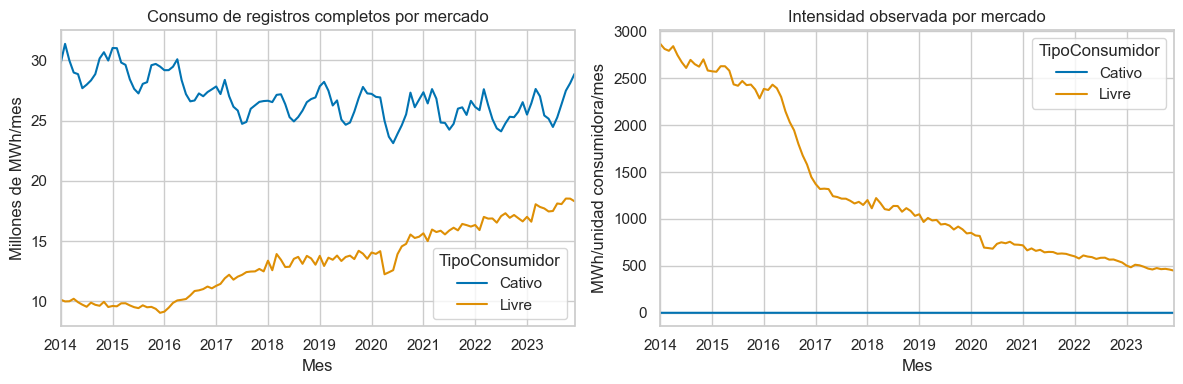

Consumo  Consumidores  MWh_por_unidad
Data       TipoConsumidor                                           
2023-10-01 Cativo          27477904.21    92740101.0            0.30
           Livre           18526118.41       39511.0          468.89
2023-11-01 Cativo          28105543.25    92781478.0            0.30
           Livre           18518344.54       40166.0          461.05
2023-12-01 Cativo          28867253.61    93097365.0            0.31
           Livre           18299310.43       40722.0          449.37

In [14]:
por_mercado = df.groupby([pd.Grouper(freq="MS"), "TipoConsumidor"])[["Consumo", "Consumidores"]].sum(min_count=1)
por_mercado["MWh_por_unidad"] = por_mercado["Consumo"] / por_mercado["Consumidores"].where(por_mercado["Consumidores"] > 0)
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
(por_mercado["Consumo"].unstack() / 1e6).plot(ax=ejes[0])
ejes[0].set(title="Consumo de registros completos por mercado", xlabel="Mes", ylabel="Millones de MWh/mes")
por_mercado["MWh_por_unidad"].unstack().plot(ax=ejes[1])
ejes[1].set(title="Intensidad observada por mercado", xlabel="Mes", ylabel="MWh/unidad consumidora/mes")
mostrar()
display(por_mercado.tail(6).round(2))

## Conclusiones y límites
Los números salen del dataset ejecutado. Los faltantes hacen que los totales sean observados,
no estimaciones completas; los no positivos requieren contexto adicional de la fuente.
No inferimos causalidad, consumo individual, población, tarifas ni energía barata a partir de este archivo.

In [15]:
anual_total = mensual["Consumo"].groupby(mensual.index.year).sum(min_count=1)
resumen = {
    "filas_originales": len(base), "filas_completas": len(df),
    "sin_alguna_medicion": len(base) - len(df), "meses": len(mensual),
    "inicio": str(base.index.min().date()), "fin": str(base.index.max().date()),
    "nulos_consumo": int(base["Consumo"].isna().sum()),
    "nulos_consumidores": int(base["Consumidores"].isna().sum()),
    "consumo_negativo": int(base["Consumo"].lt(0).sum()),
    "consumo_cero": int(base["Consumo"].eq(0).sum()),
    "pearson_consumidores_consumo": float(correlacion.loc["Consumidores", "Consumo"]),
    "media_consumo_positivo": float(resumen_distribuciones["Consumo"]["media"]),
    "mediana_consumo_positivo": float(resumen_distribuciones["Consumo"]["mediana"]),
    "cobertura_min_pct": float(mensual["cobertura_pct"].min()),
    "top_uf_mwh": top_uf.to_dict(), "consumo_anual_mwh": anual_total.to_dict(),
    "mes_media_mayor": int(patron_mes["mean"].idxmax()),
    "mes_media_menor": int(patron_mes["mean"].idxmin()),
}
display(Markdown(f"""
- Se inspeccionaron **{len(base):,} registros** de **{len(mensual)} meses**, entre {resumen['inicio']} y {resumen['fin']}.
- **{len(base) - len(df):,} registros** no tienen ambas mediciones; solo se excluyen de las comparaciones que requieren las dos.
- Hay **{resumen['consumo_negativo']} consumos negativos** y **{resumen['consumo_cero']} ceros**: se contabilizan, sin asignarles una causa no verificada.
- Entre consumos positivos, media **{resumen['media_consumo_positivo']:,.2f} MWh** y mediana **{resumen['mediana_consumo_positivo']:,.2f} MWh**, consistente con cola derecha.
- Consumo y unidades consumidoras tienen Pearson **{resumen['pearson_consumidores_consumo']:.3f}** en registros completos: asociación descriptiva.
- **{top_uf.index[0]}** lidera los totales registrados con **{top_uf.iloc[0] / 1e6:,.2f} millones de MWh** en todo el período, sin ajuste por población.
- En la media por mes calendario, el mes **{resumen['mes_media_mayor']}** es el mayor y **{resumen['mes_media_menor']}** el menor. Debe leerse junto al mapa de cada año.
"""))


- Se inspeccionaron **285,499 registros** de **120 meses**, entre 2014-01-01 y 2023-12-01.
- **13,688 registros** no tienen ambas mediciones; solo se excluyen de las comparaciones que requieren las dos.
- Hay **635 consumos negativos** y **0 ceros**: se contabilizan, sin asignarles una causa no verificada.
- Entre consumos positivos, media **17,630.61 MWh** y mediana **1,484.00 MWh**, consistente con cola derecha.
- Consumo y unidades consumidoras tienen Pearson **0.396** en registros completos: asociación descriptiva.
- **SP** lidera los totales registrados con **1,335.30 millones de MWh** en todo el período, sin ajuste por población.
- En la media por mes calendario, el mes **3** es el mayor y **6** el menor. Debe leerse junto al mapa de cada año.
